# 🌱 FarmerBud · 1. Addestramento delle 4 reti neurali

Questo notebook addestra le 4 reti che usa l'app FarmerBud (`2_FarmerBud_app_IT.ipynb`) e le salva in un unico file, `modelli.joblib`.

| Rete | Cosa prevede | Da quali dati impara |
|---|---|---|
| 1. **Resa** | la resa relativa (1,00 = anno normale) | rese vere ISTAT 2006-2025 + clima della stagione + suolo |
| 2. **Acqua** | l'acqua da irrigare (mm) | risultati della formula FAO-56: la rete deve ricostruirla da ET0, pioggia e coltura |
| 3. **Azoto** | l'azoto da distribuire (kg N/ha) | risultati delle schede dei disciplinari: la rete deve ricostruirle |
| 4. **Stabilità** | quanto la resa cambia da un anno all'altro (coefficiente di variazione, %) | oscillazione vera delle rese ISTAT in ogni provincia |

Per ogni rete: preparazione dei dati, addestramento un'epoca alla volta, **grafico dell'errore** (per vedere se
impara), esame finale su dati mai visti e confronto con una previsione **banale**. Se la rete non batte la
previsione banale, non serve: per questo il confronto c'è sempre.

**Dati:** i file della cartella `01_Datasets` (come sono stati costruiti: `01_Datasets/README_IT.md`).
Sul computer del team vengono letti da lì; su **Google Colab** il notebook li scarica da solo dal repository GitHub.

## 0. Librerie

In [1]:
# copy serve per fare una copia completa di una rete (per tenere la versione migliore).
import copy

# os controlla se un file esiste; urllib.request scarica un file da internet.
import os
import urllib.request

# joblib salva le reti su un file, per usarle nell'app.
import joblib

# matplotlib.pyplot disegna i grafici; lo chiamiamo "plt".
import matplotlib.pyplot as plt

# numpy fa calcoli su liste di numeri; lo chiamiamo "np".
import numpy as np

# pandas legge e maneggia tabelle (come Excel, ma in Python); lo chiamiamo "pd".
import pandas as pd

# sklearn è scikit-learn: ci serve il suo numero di versione, salvato insieme alle reti.
import sklearn

# mean_absolute_error calcola l'errore medio: la media di |vero - previsto|.
from sklearn.metrics import mean_absolute_error

# MLPRegressor è la rete neurale di scikit-learn che prevede un numero.
from sklearn.neural_network import MLPRegressor

# StandardScaler porta tutte le colonne sulla stessa scala (media 0, deviazione 1).
from sklearn.preprocessing import StandardScaler

## 1. Leggere i dati

In [2]:
# Il repository GitHub del progetto: da qui il notebook scarica i dati quando non li trova (es. su Colab).
REPO = "byterunnersAI/FarmerBud"


# Restituisce il percorso di un file del progetto; se non c'è, lo scarica da GitHub.
def data_file(path):
    # Sul computer del team il notebook sta in 02_AI_Model, quindi i dati sono una cartella più su.
    if os.path.exists("../" + path):
        return "../" + path
    # Altrimenti scarica il file (una volta sola) nella cartella corrente.
    name = path.split("/")[-1]
    if not os.path.exists(name):
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/{REPO}/main/{path}", name)
    return name


# Rese + clima della stagione + suolo: una riga = provincia × coltura × anno.
yield_data = pd.read_csv(data_file("01_Datasets/dataset_modello.csv"))

# Acqua di irrigazione calcolata con FAO-56 per ogni provincia × coltura × anno.
water_data = pd.read_csv(data_file("01_Datasets/interim/acqua_anni.csv"))

# Azoto calcolato con le schede dei disciplinari per ogni provincia × coltura × anno.
nitrogen_data = pd.read_csv(data_file("01_Datasets/interim/azoto_anni.csv"))

# Tabella delle colture: ci serve la resa mediana in t/ha di ognuna.
crops = pd.read_csv(data_file("01_Datasets/colture.csv"))

# Nome, regione, coordinate e quota del punto di pianura di ogni provincia.
provinces = pd.read_csv(data_file("01_Datasets/interim/punti_province.csv"))

# Stampa quante righe ha ogni tabella.
print("Resa:", len(yield_data), "· Acqua:", len(water_data), "· Azoto:", len(nitrogen_data))

Resa: 4967 · Acqua: 6600 · Azoto: 4967


## 2. Due funzioni che usiamo per tutte e 4 le reti
Invece di scrivere 4 volte lo stesso codice, lo scriviamo una volta dentro una **funzione** e la chiamiamo 4 volte.

**`train_network`** crea una rete e la addestra un'epoca alla volta. Un'**epoca** = la rete vede tutte le righe
di train una volta e aggiorna i pesi. Dopo ogni epoca misura l'errore su train e validazione e tiene da parte la
rete con l'errore di validazione più basso: dopo quel punto la rete inizierebbe a imparare a memoria (*overfitting*).

**`plot_training`** disegna i due grafici dell'errore:
- a sinistra la **loss**, l'errore che la rete usa per correggere i pesi: se scende, la rete sta imparando;
- a destra l'**errore medio** su train e validazione, nell'unità di misura della rete.

In [3]:
# Definisce la funzione: riceve i dati, la forma della rete e quante epoche fare.
def train_network(X_train, y_train, X_val, y_val, hidden, alpha, epochs, unit, batch=64, verbose=True):
    # Crea la rete (ancora vuota: i pesi sono casuali).
    net = MLPRegressor(
        hidden_layer_sizes=hidden,    # quanti neuroni in ogni strato nascosto, es. (32, 16)
        activation="relu",            # attivazione: i valori negativi diventano 0, gli altri restano uguali
        learning_rate_init=0.001,     # quanto si spostano i pesi a ogni correzione: piccolo = lento ma stabile
        alpha=alpha,                  # penalità sui pesi grandi: più è alta, meno la rete impara a memoria
        batch_size=batch,             # la rete corregge i pesi ogni "batch" righe
        random_state=42,              # pesi iniziali sempre uguali: stesso risultato a ogni esecuzione
    )
    # Liste vuote dove salvare l'errore dopo ogni epoca.
    err_train, err_val = [], []
    # La rete migliore trovata finora: all'inizio nessuna, con errore infinito.
    best_err, best_epoch, best_net = float("inf"), 0, None
    # Ripete per ogni epoca, da 1 a "epochs".
    for epoch in range(1, epochs + 1):
        # Una passata su tutto il train: la rete prevede, misura l'errore e corregge i pesi.
        net.partial_fit(X_train, y_train)
        # Errore medio sul train, riportato nell'unità di misura vera (× unit).
        err_train.append(mean_absolute_error(y_train, net.predict(X_train)) * unit)
        # Errore medio sulla validazione: dati che la rete non usa per correggere i pesi.
        err_val.append(mean_absolute_error(y_val, net.predict(X_val)) * unit)
        # Se è l'errore di validazione più basso finora, salva una copia della rete.
        if err_val[-1] < best_err:
            best_err, best_epoch, best_net = err_val[-1], epoch, copy.deepcopy(net)
    # Dice qual è stata l'epoca migliore (se verbose è vero).
    if verbose:
        print(f"Migliore: epoca {best_epoch}, errore di validazione {best_err:.2f}")
    # Restituisce la rete migliore e le curve per il grafico.
    return best_net, net.loss_curve_, err_train, err_val, best_epoch


# Definisce la funzione che disegna i due grafici dell'errore.
def plot_training(title, loss, err_train, err_val, best_epoch, unit_label):
    # Numeri delle epoche per l'asse orizzontale.
    epochs = range(1, len(loss) + 1)
    # Una figura con due grafici affiancati: "left" e "right".
    fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4))
    # A sinistra: la loss di ogni epoca.
    left.plot(epochs, loss, color="tab:blue")
    left.set_title(f"{title}: loss durante l'addestramento")
    left.set_xlabel("Epoca")
    left.set_ylabel("Loss")
    # A destra: errore medio su train (blu) e validazione (arancione).
    right.plot(epochs, err_train, label="Train", color="tab:blue")
    right.plot(epochs, err_val, label="Validazione", color="tab:orange")
    # Linea tratteggiata sull'epoca della rete migliore.
    right.axvline(best_epoch, color="gray", linestyle="--", label=f"Rete migliore ({best_epoch})")
    right.set_title(f"{title}: errore medio")
    right.set_xlabel("Epoca")
    right.set_ylabel(unit_label)
    right.legend()
    # Sistema gli spazi e mostra la figura.
    plt.tight_layout()
    plt.show()


# Dizionario vuoto dove metteremo le 4 reti pronte per l'app.
models = {}

## 3. Rete 1: resa
**Input:** la coltura, 13 colonne sul clima della stagione, 6 sul suolo, 3 sulla posizione.
**Risposta:** `resa_relativa` (resa divisa per la resa normale della coltura: 1,00 = normale, 0,80 = 20% in meno).
**Divisione per anno:** train 2006-2018, validazione 2019-2021, test 2022-2025 (c'è la siccità del 2022).
Dividiamo per anno perché nella realtà la rete deve prevedere anni futuri.

Migliore: epoca 138, errore di validazione 12.78


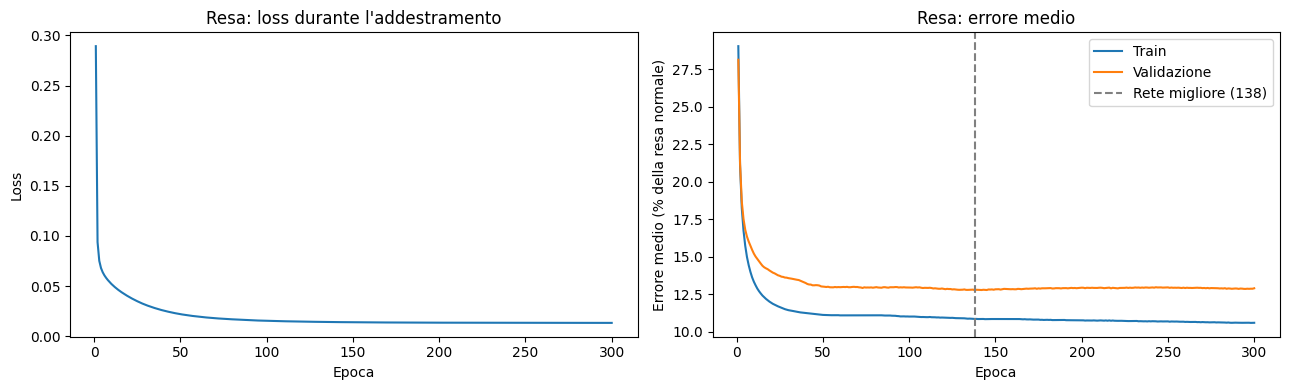

In [4]:
# Colonne da non dare alla rete: servono solo per dividere i dati, o sono la risposta.
not_inputs = ["cod_provincia", "anno", "periodo", "resa_relativa"]

# Toglie quelle colonne; get_dummies trasforma la coltura (testo) in una colonna 0/1 per ogni coltura.
X = pd.get_dummies(yield_data.drop(columns=not_inputs), columns=["cod_coltura"], dtype=float)

# La risposta giusta.
y = yield_data["resa_relativa"]

# Vero/falso per ogni riga: in quale parte va.
train = yield_data["anno"] <= 2018
val = yield_data["anno"].between(2019, 2021)
test = yield_data["anno"] >= 2022

# Lo scaler impara media e deviazione solo dal train, per non sbirciare negli altri anni.
scaler = StandardScaler().fit(X[train])

# Addestra la rete: 2 strati da 32 e 16 neuroni, alpha 0,1 (scelto provando 0,001, 0,1 e 1 sulla validazione).
net, loss, err_train, err_val, best = train_network(
    scaler.transform(X[train]), y[train], scaler.transform(X[val]), y[val],
    hidden=(32, 16), alpha=0.1, epochs=300, unit=100)

# Disegna i grafici dell'errore (× 100 = errore in % della resa normale).
plot_training("Resa", loss, err_train, err_val, best, "Errore medio (% della resa normale)")

In [5]:
# La rete prevede la resa relativa per ogni riga del test.
prediction = net.predict(scaler.transform(X[test]))

# Previsione banale: ogni coltura rende come la sua media degli anni 2006-2021.
naive = yield_data.loc[test, "cod_coltura"].map(yield_data[train | val].groupby("cod_coltura")["resa_relativa"].mean())

# Confronta i due errori medi, in % della resa normale.
print(f"Errore della rete: {mean_absolute_error(y[test], prediction) * 100:.1f}%")
print(f"Errore della previsione banale: {mean_absolute_error(y[test], naive) * 100:.1f}%")

# Tabella del 2022 (siccità): resa vera, della rete e banale, media per coltura.
year_2022 = yield_data.loc[test, ["anno", "cod_coltura"]].assign(vera=y[test], rete=prediction, banale=naive)
print(year_2022[year_2022["anno"] == 2022].groupby("cod_coltura")[["vera", "rete", "banale"]].mean().round(2))

# Salva rete, scaler e ordine delle colonne: all'app servono tutti e tre.
models["yield"] = {"net": net, "scaler": scaler, "columns": list(X.columns)}

Errore della rete: 14.4%
Errore della previsione banale: 15.0%
             vera  rete  banale
cod_coltura                    
BARLEY       1.10  1.03    1.00
BEETS        0.77  0.92    0.99
COMMEAT      1.02  1.06    1.01
MAIZE        0.81  0.89    0.99
RAPE         1.00  1.01    0.95
RICE         0.87  1.00    1.01
SORGH        0.87  0.92    0.98
SOYA         0.85  0.93    0.99
SUNFLO       0.96  0.89    0.98
WHEATD       1.01  1.07    0.97


### 3b. La prova più dura: province mai viste
Nell'app il campo dell'agricoltore è quasi sempre un **luogo nuovo**. Simuliamolo: per ognuna delle 33 province
addestriamo una rete **senza** quella provincia e le chiediamo di prevedere solo lei (*leave-one-province-out*).
Ci vuole circa un minuto.

Misuriamo due cose:
1. **L'errore medio**, come prima, contro la previsione banale (media della coltura nelle altre province).
2. **La classifica**: è il vero lavoro dell'app. Per ogni provincia prendiamo le 3 colture che sono andate meglio
   davvero e contiamo quante ne indovina la rete, quante la regola banale e quante il puro caso.

Guardiamo anche l'errore **per regione**, per vedere se la rete funziona peggio in una zona.

In [6]:
# Qui salveremo, per ogni riga, la previsione della rete e quella banale fatte "senza vedere" la sua provincia.
left_out = yield_data[["cod_provincia", "cod_coltura", "anno", "resa_relativa"]].copy()
left_out["network"], left_out["naive"] = 0.0, 0.0

# Tutte le colonne di input della rete della resa (le stesse della sezione 3).
X = pd.get_dummies(yield_data.drop(columns=not_inputs), columns=["cod_coltura"], dtype=float)
y = yield_data["resa_relativa"]

# Ripete per ogni provincia.
for province in yield_data["cod_provincia"].unique():
    # Vero per le righe della provincia lasciata fuori.
    out = yield_data["cod_provincia"] == province
    # Validazione: le altre province nel 2019-2021 (serve solo a scegliere l'epoca). Train: le altre province negli altri anni.
    val = ~out & yield_data["anno"].between(2019, 2021)
    train = ~out & ~val
    scaler_lo = StandardScaler().fit(X[train])
    # Stessa rete della sezione 3, con 150 epoche per fare prima e senza stampare niente.
    net_lo = train_network(scaler_lo.transform(X[train]), y[train], scaler_lo.transform(X[val]), y[val],
                           hidden=(32, 16), alpha=0.1, epochs=150, unit=100, verbose=False)[0]
    # Previsione della rete per la provincia mai vista.
    left_out.loc[out, "network"] = net_lo.predict(scaler_lo.transform(X[out]))
    # Previsione banale: media della coltura nelle altre province.
    left_out.loc[out, "naive"] = left_out.loc[out, "cod_coltura"].map(yield_data[~out].groupby("cod_coltura")["resa_relativa"].mean())

# 1. Errore medio di rete e regola banale, in % della resa normale.
print(f"Errore della rete: {mean_absolute_error(left_out['resa_relativa'], left_out['network']) * 100:.1f}%")
print(f"Errore della previsione banale: {mean_absolute_error(left_out['resa_relativa'], left_out['naive']) * 100:.1f}%")

Errore della rete: 15.3%
Errore della previsione banale: 15.1%


In [7]:
# 2. Classifica. Resa relativa media di ogni coltura in ogni provincia: vera, della rete, banale.
averages = left_out.groupby(["cod_provincia", "cod_coltura"])[["resa_relativa", "network", "naive"]].mean()

# Per ogni provincia con almeno 5 colture: quante delle 3 migliori vere indovinano rete, regola banale e caso.
hits = []
for province, here in averages.groupby(level="cod_provincia"):
    if len(here) < 5:
        continue
    true_top3 = set(here["resa_relativa"].nlargest(3).index)
    hits.append({"rete": len(true_top3 & set(here["network"].nlargest(3).index)) / 3,
                 "regola banale": len(true_top3 & set(here["naive"].nlargest(3).index)) / 3,
                 "caso": 3 / len(here)})

# Media su tutte le province, in %.
print("Colture migliori indovinate (su 3), in media, %")
print((pd.DataFrame(hits).mean() * 100).round(0))

Colture migliori indovinate (su 3), in media, %
rete             49.0
regola banale    41.0
caso             35.0
dtype: float64


In [8]:
# Errore medio per regione: la rete funziona allo stesso modo ovunque?
left_out = left_out.merge(provinces[["cod_provincia", "provincia", "regione"]], on="cod_provincia")
left_out["errore_rete"] = (left_out["network"] - left_out["resa_relativa"]).abs() * 100
left_out["errore_banale"] = (left_out["naive"] - left_out["resa_relativa"]).abs() * 100
print(left_out.groupby("regione")[["errore_rete", "errore_banale"]].mean().round(1))

# Dove sbaglia di più: le 5 righe con l'errore più grande.
print(left_out.nlargest(5, "errore_rete")[["provincia", "anno", "cod_coltura", "resa_relativa", "network", "naive"]].round(2))

                errore_rete  errore_banale
regione                                   
Emilia-Romagna         14.7           14.5
Lombardia              15.4           15.1
Piemonte               17.8           18.0
Veneto                 13.5           13.3
    provincia  anno cod_coltura  resa_relativa  network  naive
392    Biella  2012       MAIZE           1.60     0.78   0.99
210    Torino  2025        SOYA           1.51     0.74   1.00
432    Biella  2010        SOYA           1.43     0.67   1.00
343  Vercelli  2011      SUNFLO           0.32     1.06   0.99
342  Vercelli  2010      SUNFLO           0.32     1.05   0.99


## 4. Rete 2: acqua di irrigazione
**Input:** ET0 del ciclo (quanta acqua "chiede" l'aria dalla semina al raccolto), pioggia del ciclo, coltura.
**Risposta:** acqua da irrigare in mm, calcolata con la formula FAO-56. È un **esperimento di verifica**: la rete
deve ricostruire una formula che conosciamo, partendo dagli ingredienti grezzi.
La risposta è divisa per 100 (250 mm diventa 2,5): la rete impara meglio con numeri vicini a 1.

Migliore: epoca 11, errore di validazione 28.37


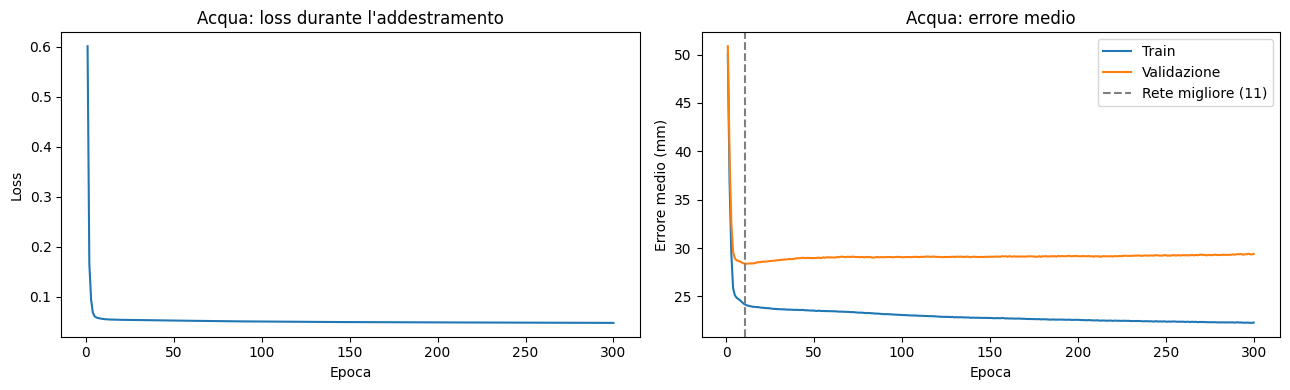

Errore della rete: 30.9 mm
Errore della previsione banale: 73.4 mm


In [9]:
# Input: ET0 e pioggia del ciclo + la coltura trasformata in colonne 0/1.
X = pd.get_dummies(water_data[["et0_ciclo_mm", "pioggia_ciclo_mm", "cod_coltura"]], columns=["cod_coltura"], dtype=float)

# La risposta giusta in centinaia di mm.
y = water_data["irrigazione_mm"] / 100

# Stessa divisione per anno della rete della resa.
train = water_data["anno"] <= 2018
val = water_data["anno"].between(2019, 2021)
test = water_data["anno"] >= 2022

# Scaler allenato solo sul train.
scaler = StandardScaler().fit(X[train])

# alpha piccolo: i dati vengono da una formula, non hanno "rumore".
net, loss, err_train, err_val, best = train_network(
    scaler.transform(X[train]), y[train], scaler.transform(X[val]), y[val],
    hidden=(32, 16), alpha=0.0001, epochs=300, unit=100)

# Grafici dell'errore, in mm.
plot_training("Acqua", loss, err_train, err_val, best, "Errore medio (mm)")

# Previsione sul test in mm; clip(min=0) perché l'acqua non può essere negativa.
prediction = (net.predict(scaler.transform(X[test])) * 100).clip(min=0)

# Previsione banale: acqua media della coltura negli anni 2006-2021.
naive = water_data.loc[test, "cod_coltura"].map(water_data[train | val].groupby("cod_coltura")["irrigazione_mm"].mean())

# Confronta i due errori medi, in mm.
print(f"Errore della rete: {mean_absolute_error(y[test] * 100, prediction):.1f} mm")
print(f"Errore della previsione banale: {mean_absolute_error(y[test] * 100, naive):.1f} mm")

# Salva la rete per l'app.
models["water"] = {"net": net, "scaler": scaler, "columns": list(X.columns)}

## 5. Rete 3: azoto
**Input:** resa attesa (t/ha), pioggia ottobre-febbraio, coltura precedente erba medica (0/1), sostanza organica
(-1 bassa, 0 normale, 1 alta), residui interrati (0/1), coltura.
**Risposta:** azoto in kg N/ha, calcolato con le schede dei disciplinari. Anche questo è un esperimento di verifica.
Le scelte dell'agricoltore nei dati ISTAT non esistono: nel file sono simulate a caso (vedi `s8_dataset_azoto.py`).

Migliore: epoca 500, errore di validazione 5.87


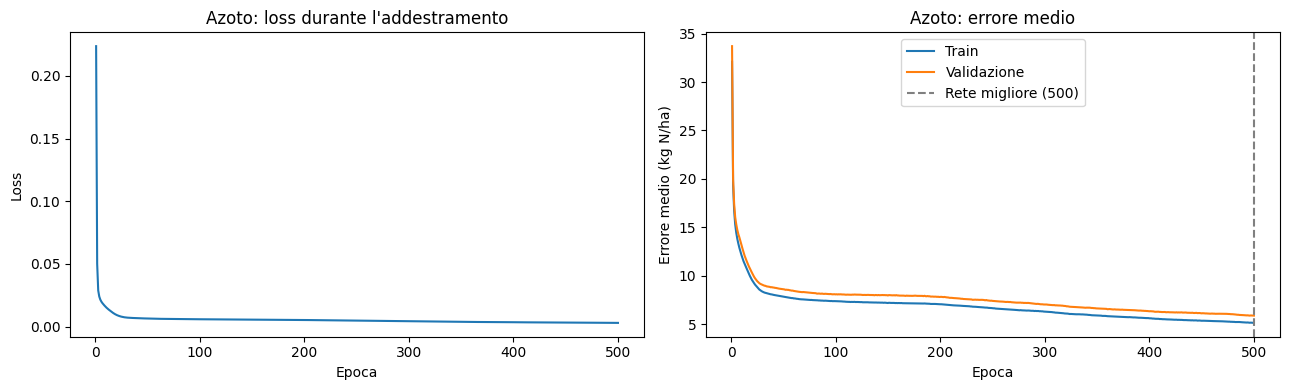

Errore della rete: 6.2 kg/ha
Errore della previsione banale: 19.6 kg/ha


In [10]:
# Le colonne numeriche di input.
nitrogen_inputs = ["resa_t_ha", "pioggia_ott_feb_mm", "dopo_medica", "sostanza_organica", "residui_interrati"]

# Input numerici + coltura trasformata in colonne 0/1.
X = pd.get_dummies(nitrogen_data[nitrogen_inputs + ["cod_coltura"]], columns=["cod_coltura"], dtype=float)

# La risposta giusta in centinaia di kg/ha.
y = nitrogen_data["azoto_kg_ha"] / 100

# Stessa divisione per anno.
train = nitrogen_data["anno"] <= 2018
val = nitrogen_data["anno"].between(2019, 2021)
test = nitrogen_data["anno"] >= 2022

# Scaler allenato solo sul train.
scaler = StandardScaler().fit(X[train])

# 500 epoche: con 300 l'errore stava ancora scendendo.
net, loss, err_train, err_val, best = train_network(
    scaler.transform(X[train]), y[train], scaler.transform(X[val]), y[val],
    hidden=(32, 16), alpha=0.0001, epochs=500, unit=100)

# Grafici dell'errore, in kg/ha.
plot_training("Azoto", loss, err_train, err_val, best, "Errore medio (kg N/ha)")

# Previsione sul test in kg/ha, mai sotto zero.
prediction = (net.predict(scaler.transform(X[test])) * 100).clip(min=0)

# Previsione banale: dose media della coltura negli anni 2006-2021.
naive = nitrogen_data.loc[test, "cod_coltura"].map(nitrogen_data[train | val].groupby("cod_coltura")["azoto_kg_ha"].mean())

# Confronta i due errori medi, in kg/ha.
print(f"Errore della rete: {mean_absolute_error(y[test] * 100, prediction):.1f} kg/ha")
print(f"Errore della previsione banale: {mean_absolute_error(y[test] * 100, naive):.1f} kg/ha")

# Salva la rete per l'app.
models["nitrogen"] = {"net": net, "scaler": scaler, "columns": list(X.columns)}

## 6. Rete 4: stabilità negli anni
**Cosa vuol dire stabile.** Per ogni provincia e coltura guardiamo la resa relativa anno per anno e calcoliamo il
**coefficiente di variazione** (CV) = deviazione standard ÷ media × 100. CV 10% = la resa oscilla poco; CV 25% = molto.
Teniamo solo le coppie provincia × coltura con almeno 10 anni di dati.

**Input:** il clima **medio** della stagione negli anni, **quanto cambia** il clima da un anno all'altro (deviazione
standard di pioggia, bilancio idrico, temperature massime, giorni sopra 35 °C, periodo secco), suolo, posizione, coltura.

**Divisione per provincia.** Qui c'è una sola riga per provincia × coltura, quindi non si può dividere per anno:
teniamo da parte 6 province per la validazione e 7 per il test, scelte a caso con un seme fisso. È la prova più
vicina all'app, dove il campo dell'agricoltore è un luogo nuovo.

**Attenzione:** sono solo circa 250 righe. Per questo la rete è piccolissima (8 neuroni) e `alpha` è alto (3):
con così pochi dati una rete grande imparerebbe a memoria.

255 righe (provincia × coltura)


Migliore: epoca 257, errore di validazione 3.35


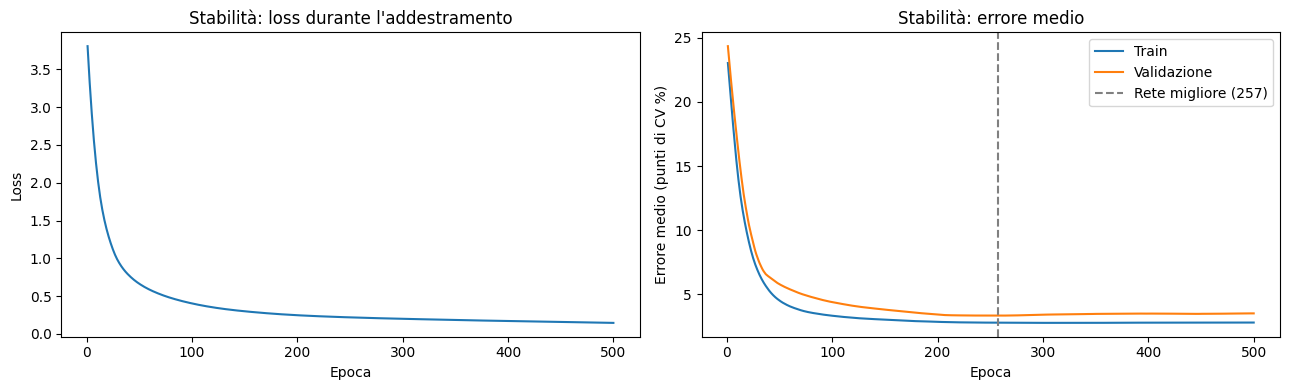

Errore della rete: 3.8 punti di CV
Errore della previsione banale: 4.5 punti di CV


In [11]:
# Le 13 colonne sul clima della stagione.
climate = ["temp_media", "temp_max_media", "temp_min_media", "pioggia_mm", "et0_mm", "bilancio_idrico_mm",
           "radiazione_MJ_m2", "umidita_media", "vento_medio_m_s", "gradi_giorno", "giorni_sopra_35",
           "giorni_gelo", "periodo_secco_max_giorni"]

# Le colonne di cui misuriamo anche quanto cambiano da un anno all'altro.
climate_spread = ["bilancio_idrico_mm", "pioggia_mm", "temp_max_media", "giorni_sopra_35", "periodo_secco_max_giorni"]

# Suolo e posizione: sono uguali in tutti gli anni di una provincia.
place = ["ph", "argilla_pct", "sabbia_pct", "limo_pct", "carbonio_organico_g_kg", "azoto_g_kg", "lat", "lon", "quota_m"]

# Raggruppa le righe per provincia e coltura.
groups = yield_data.groupby(["cod_provincia", "cod_coltura"])

# Una riga per gruppo: clima medio, quanto cambia il clima (_std), suolo e posizione, numero di anni.
stability_data = (groups[climate].mean()
                  .join(groups[climate_spread].std().add_suffix("_std"))
                  .join(groups[place].first())
                  .join(groups.size().rename("years")))

# La risposta: il coefficiente di variazione della resa relativa, in %.
stability_data["cv_pct"] = groups["resa_relativa"].std() / groups["resa_relativa"].mean() * 100

# Tiene solo i gruppi con almeno 10 anni e riporta provincia e coltura come colonne normali.
stability_data = stability_data[stability_data["years"] >= 10].reset_index()
print(len(stability_data), "righe (provincia × coltura)")

# Elenco delle province mescolato a caso, sempre nello stesso modo (seme 0).
province_list = sorted(stability_data["cod_provincia"].unique())
np.random.default_rng(0).shuffle(province_list)

# Le prime 7 province vanno nel test, le 6 dopo nella validazione, le altre nel train.
test = stability_data["cod_provincia"].isin(province_list[:7])
val = stability_data["cod_provincia"].isin(province_list[7:13])
train = ~test & ~val

# Input: tutto tranne provincia, anni e risposta; la coltura diventa colonne 0/1.
X = pd.get_dummies(stability_data.drop(columns=["cod_provincia", "years", "cv_pct"]), columns=["cod_coltura"], dtype=float)

# La risposta divisa per 10 (CV 15% diventa 1,5).
y = stability_data["cv_pct"] / 10

# Scaler allenato solo sul train.
scaler = StandardScaler().fit(X[train])

# Rete minuscola (8 neuroni), alpha alto (3), batch piccolo perché le righe sono poche.
net, loss, err_train, err_val, best = train_network(
    scaler.transform(X[train]), y[train], scaler.transform(X[val]), y[val],
    hidden=(8,), alpha=3, epochs=500, unit=10, batch=32)

# Grafici dell'errore, in punti di CV.
plot_training("Stabilità", loss, err_train, err_val, best, "Errore medio (punti di CV %)")

# Previsione sul test, in % di CV.
prediction = net.predict(scaler.transform(X[test])) * 10

# Previsione banale: CV mediano della coltura nelle province di train e validazione.
naive = stability_data.loc[test, "cod_coltura"].map(stability_data[train | val].groupby("cod_coltura")["cv_pct"].median())

# Confronta i due errori medi.
print(f"Errore della rete: {mean_absolute_error(y[test] * 10, prediction):.1f} punti di CV")
print(f"Errore della previsione banale: {mean_absolute_error(y[test] * 10, naive):.1f} punti di CV")

# Salva la rete per l'app, con l'elenco delle colonne di clima che servono per costruire gli input.
models["stability"] = {"net": net, "scaler": scaler, "columns": list(X.columns),
                       "climate": climate, "climate_spread": climate_spread}

## 7. Salvare tutto in un unico file per l'app
Insieme alle 4 reti salviamo:
- la **resa mediana in t/ha** di ogni coltura, per trasformare la resa relativa in t/ha;
- la **tabella delle province** (coordinate e suolo), per la mappa e per il suolo di riserva se SoilGrids non risponde.

In [12]:
# Dizionario coltura -> resa mediana 2006-2021 in t/ha.
models["crop_median_t_ha"] = dict(zip(crops["cod_coltura"], crops["resa_mediana_padana_2006_2021_t_ha"]))

# Una riga per provincia con suolo e posizione, presa dai dati della resa (sono uguali in tutti gli anni).
soil = yield_data.groupby("cod_provincia")[place].first().reset_index()

# Aggiunge il nome della provincia e del comune usato come punto.
models["provinces"] = soil.merge(provinces[["cod_provincia", "provincia", "comune_punto"]], on="cod_provincia")

# La versione di scikit-learn: l'app avvisa se la sua è diversa.
models["sklearn_version"] = sklearn.__version__

# Scrive tutto su un unico file.
joblib.dump(models, "modelli.joblib")
print("Salvato modelli.joblib:", list(models))

Salvato modelli.joblib: ['yield', 'water', 'nitrogen', 'stability', 'crop_median_t_ha', 'provinces', 'sklearn_version']
